# Ingeniería de características (`02_features.ipynb`) — OralSolutions

## 1. Problema y momento de predicción

- **Unidad de predicción:** sesión clínica completada de un plan de tratamiento con continuidad pendiente (`numero_sesion < sesiones_planificadas`).
- **Objetivo:** estimar el riesgo de **no registrar otra sesión completada del mismo plan dentro de los 60 días posteriores** a la sesión de referencia (`abandono_60d = 1`). `abandono_60d = 0` indica que sí se observó continuidad dentro de ese período.
- **Momento de inferencia:** cierre de la sesión actual (`fecha_realizada`). Ningún dato posterior a ese instante debe entrar en las características.
- **Procedencia del target:** se reconstruyó a partir de los eventos completados en `GOLD.FACT_SESIONES_TRATAMIENTO`, mientras que los predictores proceden de la OBT. Las fechas de continuidad posteriores se usaron **solo para etiquetar**, no como entradas del modelo.
- **Control temporal:** el dataset excluye observaciones sin 60 días completos de seguimiento al final del historial. La división temporal y la maduración de etiquetas se centralizan en `src/pipeline.py`.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

CANDIDATAS = [
    Path("../data/processed/obt_riesgo_abandono.csv"),
    Path("data/processed/obt_riesgo_abandono.csv"),
]
RUTA = next(p for p in CANDIDATAS if p.exists())
TARGET = "abandono_60d"
FECHAS = ["fecha_realizada", "fecha_inicio_plan"]

df = pd.read_csv(RUTA, parse_dates=FECHAS)
print(f"Dataset cargado: {df.shape[0]:,} filas × {df.shape[1]} columnas | Target '{TARGET}' tasa = {df[TARGET].mean():.2%}")
df.head()

Dataset cargado: 2,377 filas × 21 columnas | Target 'abandono_60d' tasa = 13.50%


,sesion_key,paciente_key,plan_tratamiento_id,cita_id,odontologo_key,procedimiento_key,codigo_procedimiento,nombre_procedimiento,duracion_estimada_min,fecha_realizada,fecha_inicio_plan,numero_sesion,sesiones_planificadas,sesiones_previas,cancelaciones_previas,inasistencias_previas,dias_desde_inicio_plan,edad_en_atencion,dia_semana_atencion,mes_atencion,abandono_60d
0,1215,434,535,1194,1,10,CROWN,Porcelain crown,75,2024-01-02,2024-01-02,1,2,0,0,0,0,45,2,1,0
1,3865,1441,1720,3369,5,10,CROWN,Porcelain crown,75,2024-01-10,2024-01-10,1,3,0,0,0,0,33,3,1,1
2,6646,2453,2955,5696,5,5,FILL2,"Filling, two surfaces",50,2024-01-11,2024-01-11,1,2,0,0,0,0,26,4,1,0
3,1049,371,453,1049,2,10,CROWN,Porcelain crown,75,2024-01-16,2024-01-16,1,2,0,0,0,0,64,2,1,0
4,3127,1162,1388,2769,2,8,WHITEN,Whitening session,60,2024-01-25,2024-01-25,1,4,0,0,0,0,62,4,1,0


Se cargaron **2.377 registros** y **21 columnas** del CSV procesado `data/processed/obt_riesgo_abandono.csv`, con sesiones de referencia comprendidas entre **2024-01-02 y 2025-11-01**. El target corregido registra **321 abandonos (13,50 %)** y **2.056 continuidades (86,50 %)**. Este desbalance reemplaza la distribución del experimento anterior y obliga a reevaluar las conclusiones sobre las features.


## 2. Diseño de variables derivadas a partir del EDA

Se construyen **cuatro features candidatas** (tres numéricas y una categórica) utilizando información disponible al cierre de cada sesión. El EDA no muestra relaciones deterministas con el abandono; por tanto, **no se presupone que estas variables mejoren la predicción**.

| Feature derivada | Cálculo | Relación con el nuevo EDA | Tipo |
|---|---|---|---|
| `progreso_plan` | `numero_sesion / sesiones_planificadas` | **Hallazgo 1:** el abandono es 13,9 % con una sesión restante, 14,2 % con dos y 10,4 % con tres; el avance podría capturar una relación no lineal, pero no destaca por sí solo. | Numérica |
| `ritmo_dias_por_sesion` | `dias_desde_inicio_plan / numero_sesion` | **Hallazgo 2:** el tiempo desde el inicio presenta cola derecha (asimetría 1,63); normalizar por número de sesión permite explorar la cadencia del plan. | Numérica |
| `friccion_previa` | `cancelaciones_previas + inasistencias_previas` | **Hallazgo 2:** ambas variables tienen colas derechas (asimetrías 3,53 y 4,56); se explora una señal agregada de eventos anteriores. | Numérica |
| `complejidad_proc` | Agrupación `EXTRACT`, `FILL1`, `FILL2` frente al resto | **Hallazgo 3:** las tasas de abandono por procedimiento se sitúan aproximadamente entre 12,9 % y 16,0 %; la agrupación es una **clasificación operativa del experimento**, no una medida clínica validada de complejidad. | Categórica |


In [2]:
df_feat = df.copy()

# 1. Progreso relativo del plan de tratamiento (Hallazgo 1)
df_feat["progreso_plan"] = df_feat["numero_sesion"] / df_feat["sesiones_planificadas"]

# 2. Ritmo promedio de días transcurridos por sesión atendida (Hallazgo 2)
df_feat["ritmo_dias_por_sesion"] = df_feat["dias_desde_inicio_plan"] / df_feat["numero_sesion"]

# 3. Fricción histórica acumulada antes de la sesión actual (Hallazgo 2)
df_feat["friccion_previa"] = df_feat["cancelaciones_previas"] + df_feat["inasistencias_previas"]

# 4. Agrupación clínica de complejidad del procedimiento (Hallazgo 3)
df_feat["complejidad_proc"] = np.where(
    df_feat["codigo_procedimiento"].isin(["EXTRACT", "FILL1", "FILL2"]),
    "restaurativo_corto",
    "extenso_especializado",
)

NUEVAS_NUM = ["progreso_plan", "ritmo_dias_por_sesion", "friccion_previa"]
NUEVAS_CAT = ["complejidad_proc"]

display(df_feat[NUEVAS_NUM + NUEVAS_CAT].describe(include="all").T.round(3))
df_feat[["numero_sesion", "sesiones_planificadas", "dias_desde_inicio_plan",
        "cancelaciones_previas", "inasistencias_previas", "codigo_procedimiento"]
        + NUEVAS_NUM + NUEVAS_CAT + [TARGET]].head(8)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
progreso_plan,2377.0,NaN,NaN,NaN,0.478579,0.150794,0.25,0.333333,0.5,0.5,0.75
ritmo_dias_por_sesion,2377.0,NaN,NaN,NaN,6.931216,9.386025,0.0,0.0,0.0,14.0,39.666667
friccion_previa,2377.0,NaN,NaN,NaN,0.161969,0.455347,0.0,0.0,0.0,0.0,3.0
complejidad_proc,2377,2,extenso_especializado,1736,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,numero_sesion,sesiones_planificadas,dias_desde_inicio_plan,cancelaciones_previas,inasistencias_previas,codigo_procedimiento,progreso_plan,ritmo_dias_por_sesion,friccion_previa,complejidad_proc,abandono_60d
0,1,2,0,0,0,CROWN,0.500000,0.0,0,extenso_especializado,0
1,1,3,0,0,0,CROWN,0.333333,0.0,0,extenso_especializado,1
2,1,2,0,0,0,FILL2,0.500000,0.0,0,restaurativo_corto,0
3,1,2,0,0,0,CROWN,0.500000,0.0,0,extenso_especializado,0
4,1,4,0,0,0,WHITEN,0.250000,0.0,0,extenso_especializado,0
5,1,2,1,0,0,FILL1,0.500000,1.0,0,restaurativo_corto,0
6,1,2,0,0,0,FILL1,0.500000,0.0,0,restaurativo_corto,0
7,1,4,26,1,0,ROOT,0.250000,26.0,1,extenso_especializado,0


**Comprobación descriptiva de las features construidas:**

- `progreso_plan`: oscila entre **0,25 y 0,75**, con mediana **0,50**. Describe el avance observado, no el desenlace futuro.
- `ritmo_dias_por_sesion`: mediana **0** y máximo aproximado **39,67 días/sesión**; su distribución es asimétrica.
- `friccion_previa`: media **0,162** y máximo **3 eventos**, con elevada concentración en cero.
- `complejidad_proc`: **1.736 (73,0 %)** registros en `extenso_especializado` y **641 (27,0 %)** en `restaurativo_corto`, según la agrupación operativa implementada.

Estas cifras describen las variables; no demuestran capacidad predictiva por sí solas.


## 3. Evidencia estadística y gráfica de asociación con el abandono

Para examinar cada feature candidata frente a `abandono_60d`, se calculan:

1. **Numéricas:** correlación de **Spearman** y prueba **Mann–Whitney U**, adecuadas como análisis exploratorios ante distribuciones asimétricas y empates.
2. **Categórica:** tabla de tasas de abandono y prueba **chi-cuadrado** de independencia para `complejidad_proc`.
3. **Gráficos:** tasas observadas de abandono por tramo o categoría.


,media_continua_0,media_abandona_1,mediana_0,mediana_1,spearman_rho,p_value_mw
feature,,,,,,
progreso_plan,0.480,0.468,0.5,0.5,-0.0251,2.22e-01
ritmo_dias_por_sesion,7.272,4.748,0.0,0.0,-0.0849,3.46e-05
friccion_previa,0.179,0.053,0.0,0.0,-0.0977,1.93e-06


,filas,tasa_abandono
complejidad_proc,,
extenso_especializado,1736,0.1313
restaurativo_corto,641,0.1451


Prueba Chi-cuadrado (complejidad_proc vs abandono_60d): chi2 = 0.64 | p-value = 4.22e-01


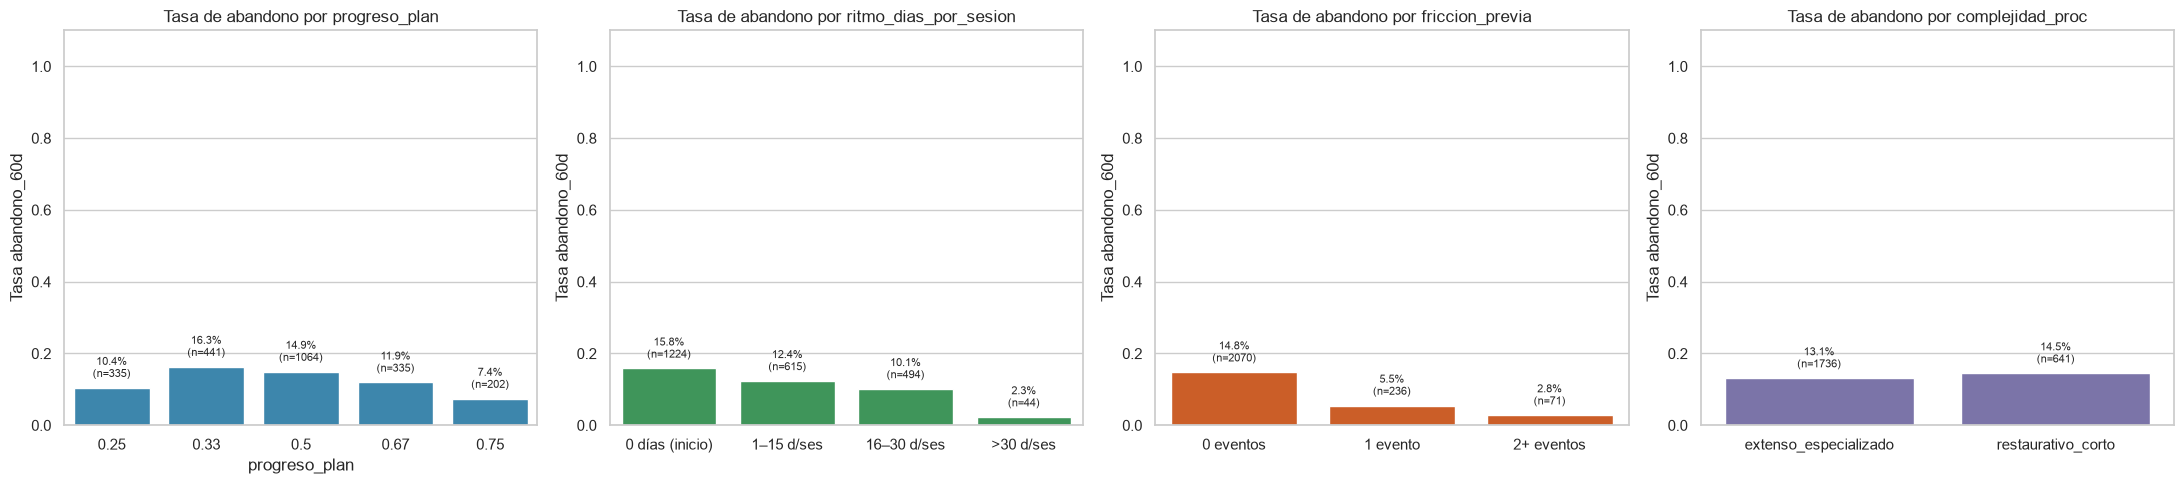

In [3]:
# 1. Tabla de evidencia estadística para features numéricas derivadas
filas_ev = []
for col in NUEVAS_NUM:
    rho, p_sp = stats.spearmanr(df_feat[col], df_feat[TARGET])
    g0 = df_feat.loc[df_feat[TARGET] == 0, col]
    g1 = df_feat.loc[df_feat[TARGET] == 1, col]
    _, p_mw = stats.mannwhitneyu(g0, g1, alternative="two-sided")
    filas_ev.append({
        "feature": col,
        "media_continua_0": round(g0.mean(), 3),
        "media_abandona_1": round(g1.mean(), 3),
        "mediana_0": round(g0.median(), 3),
        "mediana_1": round(g1.median(), 3),
        "spearman_rho": round(rho, 4),
        "p_value_mw": f"{p_mw:.2e}",
    })

display(pd.DataFrame(filas_ev).set_index("feature"))

# 2. Tabla de evidencia y Chi-cuadrado para la feature categórica derivada
ct_proc = pd.crosstab(df_feat["complejidad_proc"], df_feat[TARGET])
chi2, p_chi2, _, _ = stats.chi2_contingency(ct_proc)
res_cat = (
    df_feat.groupby("complejidad_proc")[TARGET]
    .agg(filas="size", tasa_abandono="mean")
    .round(4)
)
display(res_cat)
print(f"Prueba Chi-cuadrado (complejidad_proc vs {TARGET}): chi2 = {chi2:.2f} | p-value = {p_chi2:.2e}")

# 3. Panel gráfico 1x4 de tasa de abandono por feature derivada
fig, axes = plt.subplots(1, 4, figsize=(22, 5))

# (a) progreso_plan
g_prog = df_feat.groupby(df_feat["progreso_plan"].round(2))[TARGET].agg(["mean", "size"]).reset_index()
sns.barplot(data=g_prog, x="progreso_plan", y="mean", color="#2b8cbe", ax=axes[0])
axes[0].set_title("Tasa de abandono por progreso_plan")
axes[0].set_ylabel("Tasa abandono_60d")
axes[0].set_ylim(0, 1.1)
for i, r in g_prog.iterrows():
    axes[0].text(i, r["mean"] + 0.03, f"{r['mean']:.1%}\n(n={int(r['size'])})", ha="center", fontsize=8)

# (b) ritmo_dias_por_sesion (agrupado en tramos interpretables)
bins_ritmo = [-0.1, 0, 15, 30, 100]
labels_ritmo = ["0 días (inicio)", "1–15 d/ses", "16–30 d/ses", ">30 d/ses"]
df_feat["tramo_ritmo"] = pd.cut(df_feat["ritmo_dias_por_sesion"], bins=bins_ritmo, labels=labels_ritmo)
g_ritmo = df_feat.groupby("tramo_ritmo", observed=False)[TARGET].agg(["mean", "size"]).reset_index()
sns.barplot(data=g_ritmo, x="tramo_ritmo", y="mean", color="#31a354", ax=axes[1])
axes[1].set_title("Tasa de abandono por ritmo_dias_por_sesion")
axes[1].set_ylabel("Tasa abandono_60d")
axes[1].set_xlabel("")
axes[1].set_ylim(0, 1.1)
for i, r in g_ritmo.iterrows():
    axes[1].text(i, r["mean"] + 0.03, f"{r['mean']:.1%}\n(n={int(r['size'])})", ha="center", fontsize=8)

# (c) friccion_previa (0, 1, 2+)
df_feat["tramo_friccion"] = df_feat["friccion_previa"].clip(upper=2).map({0: "0 eventos", 1: "1 evento", 2: "2+ eventos"})
g_fric = df_feat.groupby("tramo_friccion")[TARGET].agg(["mean", "size"]).reindex(["0 eventos", "1 evento", "2+ eventos"]).reset_index()
sns.barplot(data=g_fric, x="tramo_friccion", y="mean", color="#e6550d", ax=axes[2])
axes[2].set_title("Tasa de abandono por friccion_previa")
axes[2].set_ylabel("Tasa abandono_60d")
axes[2].set_xlabel("")
axes[2].set_ylim(0, 1.1)
for i, r in g_fric.iterrows():
    axes[2].text(i, r["mean"] + 0.03, f"{r['mean']:.1%}\n(n={int(r['size'])})", ha="center", fontsize=8)

# (d) complejidad_proc
g_comp = df_feat.groupby("complejidad_proc")[TARGET].agg(["mean", "size"]).reset_index()
sns.barplot(data=g_comp, x="complejidad_proc", y="mean", color="#756bb1", ax=axes[3])
axes[3].set_title("Tasa de abandono por complejidad_proc")
axes[3].set_ylabel("Tasa abandono_60d")
axes[3].set_xlabel("")
axes[3].set_ylim(0, 1.1)
for i, r in g_comp.iterrows():
    axes[3].text(i, r["mean"] + 0.03, f"{r['mean']:.1%}\n(n={int(r['size'])})", ha="center", fontsize=8)

plt.tight_layout()
plt.show()

### Interpretación de los resultados con el target corregido

- **`progreso_plan`:** presenta **ρ = −0,0251** y **p = 0,222** (Mann–Whitney). Las medias son **0,480** en continuidad y **0,468** en abandono, con mediana **0,50** en ambos grupos. No se observa una separación individual clara; se mantiene como candidata para comprobar si aporta una interacción útil en validación temporal.
- **`ritmo_dias_por_sesion`:** muestra una asociación **débil y negativa** (**ρ = −0,0849**, **p = 3,46 × 10⁻⁵**). Su media es **7,272 días/sesión** entre quienes continúan y **4,748** entre quienes abandonan; ambas medianas son cero. La significación estadística no implica una ventaja predictiva importante.
- **`friccion_previa`:** también presenta asociación **débil y negativa** (**ρ = −0,0977**, **p = 1,93 × 10⁻⁶**). La media es **0,179** en continuidad frente a **0,053** en abandono, sin diferencia en las medianas (ambas cero). En estos datos no corresponde afirmar que más fricción aumenta el abandono; conviene revisar tamaños por tramo y evaluar su utilidad mediante CV.
- **`complejidad_proc`:** la tasa de abandono es **13,13 %** en `extenso_especializado` (**n = 1.736**) y **14,51 %** en `restaurativo_corto` (**n = 641**). La prueba chi-cuadrado **no evidencia una diferencia estadísticamente significativa** (**χ² = 0,64**, **p = 0,422**). Su valor predictivo añadido es incierto y deberá contrastarse con la variable base `codigo_procedimiento`.

**Conclusión:** ninguna de las cuatro features demuestra por sí sola una señal fuerte comparable a la observada con las etiquetas antiguas. Se conservan inicialmente como **candidatas**, y su utilidad se determinará con comparaciones reproducibles dentro del entrenamiento.


## 4. Disponibilidad temporal, codificación y esquema de predictores

### 4.1. Auditoría de disponibilidad en el instante de inferencia

La predicción se solicita **al cerrar la sesión atendida** (`fecha_realizada`). Las cuatro features se construyen exclusivamente a partir de columnas de la OBT; no utilizan las fechas de sesiones posteriores que sirvieron para determinar el target.

1. **`progreso_plan`:** se obtiene de `numero_sesion` (sesión actual) y `sesiones_planificadas` (definidas en el plan). Ambas deben corresponder al estado del plan conocido al momento de la consulta. Variable numérica; se escala dentro del `Pipeline`.
2. **`ritmo_dias_por_sesion`:** utiliza los días desde el inicio del plan hasta la sesión actual y `numero_sesion`, sin consultar eventos futuros. Numérica con asimetría; se escala dentro del `Pipeline`.
3. **`friccion_previa`:** suma cancelaciones e inasistencias históricas, que según la lógica de Spark se calculan a partir de eventos **estrictamente anteriores** a `fecha_realizada`. Numérica; se escala dentro del `Pipeline`.
4. **`complejidad_proc`:** agrupación determinista de `codigo_procedimiento`, disponible en la sesión de referencia. Es nominal; se codifica con `OneHotEncoder(handle_unknown="ignore")`, sin imponer orden artificial.

### 4.2. Esquema final propuesto en `src/pipeline.py`

- **10 numéricas:** `duracion_estimada_min`, `numero_sesion`, `sesiones_planificadas`, `cancelaciones_previas`, `inasistencias_previas`, `dias_desde_inicio_plan`, `edad_en_atencion`, `progreso_plan`, `ritmo_dias_por_sesion`, `friccion_previa`.
- **3 categóricas:** `codigo_procedimiento`, `odontologo_key`, `complejidad_proc`; codificación nominal mediante One-Hot en el preprocesador.
- **Columnas excluidas:** identificadores (`sesion_key`, `paciente_key`, `plan_tratamiento_id`, `cita_id`, `procedimiento_key`), redundancias (`sesiones_previas`, `nombre_procedimiento`), fechas usadas para el orden temporal (`fecha_realizada`, `fecha_inicio_plan`) y variables de calendario no seleccionadas (`dia_semana_atencion`, `mes_atencion`).

Se mantiene inicialmente el conjunto de **13 predictores candidatos**, sujeto a evaluación incremental mediante validación cruzada temporal. La preparación estadística y la selección del modelo se ajustarán solo a entrenamiento.


In [ ]:
FEATURES_NUM = [
    "duracion_estimada_min",
    "numero_sesion",
    "sesiones_planificadas",
    "cancelaciones_previas",
    "inasistencias_previas",
    "dias_desde_inicio_plan",
    "edad_en_atencion",
    "progreso_plan",
    "ritmo_dias_por_sesion",
    "friccion_previa",
]

FEATURES_CAT = [
    "codigo_procedimiento",
    "odontologo_key",
    "complejidad_proc",
]

FEATURES_FINALES = FEATURES_NUM + FEATURES_CAT

# Comprobaciones automáticas de integridad antes del modelado.
# Las transformaciones definitivas están centralizadas en src/pipeline.py
assert len(FEATURES_FINALES) == len(set(FEATURES_FINALES)), "Hay features duplicadas"
assert TARGET not in FEATURES_FINALES, "Fuga: el target está en las features"
assert not any(c in FEATURES_FINALES for c in ["sesion_key", "paciente_key", "plan_tratamiento_id", "cita_id", "es_ultima_observada"]), "Fuga o ID detectado"
assert df_feat[FEATURES_FINALES].isna().sum().sum() == 0, "Existen valores nulos en las features finales"

print(f"Total features seleccionadas: {len(FEATURES_FINALES)} ({len(FEATURES_NUM)} numéricas + {len(FEATURES_CAT)} categóricas)")
print("Numéricas :", FEATURES_NUM)
print("Categóricas:", FEATURES_CAT)
df_feat[FEATURES_FINALES + [TARGET]].head()

Total features seleccionadas: 13 (10 numéricas + 3 categóricas)
Numéricas : ['duracion_estimada_min', 'numero_sesion', 'sesiones_planificadas', 'cancelaciones_previas', 'inasistencias_previas', 'dias_desde_inicio_plan', 'edad_en_atencion', 'progreso_plan', 'ritmo_dias_por_sesion', 'friccion_previa']
Categóricas: ['codigo_procedimiento', 'odontologo_key', 'complejidad_proc']


,duracion_estimada_min,numero_sesion,sesiones_planificadas,cancelaciones_previas,inasistencias_previas,dias_desde_inicio_plan,edad_en_atencion,progreso_plan,ritmo_dias_por_sesion,friccion_previa,codigo_procedimiento,odontologo_key,complejidad_proc,abandono_60d
0,75,1,2,0,0,0,45,0.500000,0.0,0,CROWN,1,extenso_especializado,0
1,75,1,3,0,0,0,33,0.333333,0.0,0,CROWN,5,extenso_especializado,1
2,50,1,2,0,0,0,26,0.500000,0.0,0,FILL2,5,restaurativo_corto,0
3,75,1,2,0,0,0,64,0.500000,0.0,0,CROWN,2,extenso_especializado,0
4,60,1,4,0,0,0,62,0.250000,0.0,0,WHITEN,2,extenso_especializado,0


Las comprobaciones de esta ejecución verifican que la lista propuesta contiene **13 features** (10 numéricas y 3 categóricas), sin nombres duplicados, sin inclusión explícita del target ni de los identificadores prohibidos, y sin nulos en las columnas seleccionadas de este snapshot.


## 5. Evaluación incremental de las features derivadas

### 5.1. Objetivo

Se realiza un estudio de ablación para determinar si las cuatro características derivadas aportan información predictiva adicional frente a los predictores originales.

La comparación responde a la observación del PSet 3 sobre la necesidad de demostrar el aporte de las features, más allá de sus asociaciones estadísticas.

Se utiliza LogisticRegression con configuración fija, manteniendo el mismo preprocesamiento y los cinco pliegues temporales purgados de 60 días del notebook 03.

Se comparan seis configuraciones:

1. Variables originales, sin las cuatro derivadas.
2. Todas las variables: 9 originales y 4 derivadas.
3. Modelo completo sin `progreso_plan`.
4. Modelo completo sin `ritmo_dias_por_sesion`.
5. Modelo completo sin `friccion_previa`.
6. Modelo completo sin `complejidad_proc`.

La métrica principal es Average Precision (PR-AUC). Se informa la media, la desviación estándar y las diferencias por pliegue.

**Control de fuga:** solo se utilizan observaciones de entrenamiento y validación temporal. El hold-out de 826 registros permanece excluido.

El análisis es complementario: no modifica el champion, sus hiperparámetros ni las versiones registradas en MLflow.


In [2]:
# ============================================================
# 5.2. Ablación de características con CV temporal purgada
# ============================================================

import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd

from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import average_precision_score
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from src.pipeline import (
    cargar_datos,
    construir_features,
    obtener_datos_divididos,
    FECHA_CORTE,
    FECHA_EVENTO,
    FEATURES_FINALES,
    SEMILLA,
)

# ------------------------------------------------------------
# A. Datos y fechas: mismo procedimiento del notebook 03
# ------------------------------------------------------------

X_train, _, y_train, _ = obtener_datos_divididos()

base = construir_features(cargar_datos())

HORIZONTE_DIAS = 60

limite_train = (
    pd.Timestamp(FECHA_CORTE)
    - pd.Timedelta(days=HORIZONTE_DIAS)
)

dates_train = base.loc[
    base[FECHA_EVENTO] <= limite_train,
    FECHA_EVENTO,
].reset_index(drop=True)

X_train = X_train.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)

assert len(X_train) == len(y_train) == len(dates_train) == 1195
assert dates_train.is_monotonic_increasing

# ------------------------------------------------------------
# B. Construir CV temporal con purga de 60 días
# ------------------------------------------------------------

fechas_unicas = pd.Index(
    dates_train.drop_duplicates().sort_values()
)

cv_temporal = []

for idx_fechas_train, idx_fechas_val in TimeSeriesSplit(
    n_splits=5
).split(fechas_unicas):

    inicio_val = fechas_unicas[idx_fechas_val[0]]
    fin_val = fechas_unicas[idx_fechas_val[-1]]

    limite_etiquetas = (
        inicio_val - pd.Timedelta(days=HORIZONTE_DIAS)
    )

    idx_train = np.flatnonzero(
        (dates_train <= limite_etiquetas).to_numpy()
    )

    idx_val = np.flatnonzero(
        (
            (dates_train >= inicio_val)
            & (dates_train <= fin_val)
        ).to_numpy()
    )

    assert len(idx_train) > 0
    assert len(idx_val) > 0

    assert y_train.iloc[idx_train].nunique() == 2
    assert y_train.iloc[idx_val].nunique() == 2

    assert (
        dates_train.iloc[idx_train].max()
        + pd.Timedelta(days=HORIZONTE_DIAS)
        <= dates_train.iloc[idx_val].min()
    )

    cv_temporal.append((idx_train, idx_val))

print("Observaciones entrenamiento:", len(X_train))
print("Pliegues temporales:", len(cv_temporal))

# ------------------------------------------------------------
# C. Definir las características
# ------------------------------------------------------------

derivadas = [
    "progreso_plan",
    "ritmo_dias_por_sesion",
    "friccion_previa",
    "complejidad_proc",
]

originales = [
    c for c in FEATURES_FINALES
    if c not in derivadas
]

completas = list(FEATURES_FINALES)

assert len(originales) == 9
assert len(completas) == 13

configuraciones = {
    "A_Originales": originales,
    "B_Completas": completas,
}

for feature in derivadas:
    configuraciones[f"Sin_{feature}"] = [
        c for c in completas
        if c != feature
    ]

# ------------------------------------------------------------
# D. Construir pipeline para cada subconjunto
# ------------------------------------------------------------

categoricas_disponibles = [
    "codigo_procedimiento",
    "odontologo_key",
    "complejidad_proc",
]

def crear_modelo_ablacion(columnas):

    categoricas = [
        c for c in columnas
        if c in categoricas_disponibles
    ]

    numericas = [
        c for c in columnas
        if c not in categoricas
    ]

    transformador_numerico = Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", RobustScaler()),
    ])

    transformador_categorico = Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        (
            "codificar",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
            ),
        ),
    ])

    preprocesador = ColumnTransformer([
        ("num", transformador_numerico, numericas),
        ("cat", transformador_categorico, categoricas),
    ])

    return Pipeline([
        ("preprocesamiento", preprocesador),
        (
            "modelo",
            LogisticRegression(
                max_iter=1000,
                random_state=SEMILLA,
            ),
        ),
    ])

# ------------------------------------------------------------
# E. Evaluación: mismos cinco pliegues para todos
# ------------------------------------------------------------

resultados = []
resultados_pliegues = []

for nombre, columnas in configuraciones.items():

    ap_pliegues = []

    for numero, (idx_train, idx_val) in enumerate(
        cv_temporal, start=1
    ):

        modelo = crear_modelo_ablacion(columnas)

        modelo.fit(
            X_train.iloc[idx_train][columnas],
            y_train.iloc[idx_train],
        )

        probabilidades = modelo.predict_proba(
            X_train.iloc[idx_val][columnas]
        )[:, 1]

        ap = average_precision_score(
            y_train.iloc[idx_val],
            probabilidades,
        )

        ap_pliegues.append(float(ap))

        resultados_pliegues.append({
            "configuracion": nombre,
            "pliegue": numero,
            "pr_auc": float(ap),
        })

    resultados.append({
        "configuracion": nombre,
        "n_features": len(columnas),
        "pr_auc_cv_mean": np.mean(ap_pliegues),
        "pr_auc_cv_std": np.std(ap_pliegues, ddof=1),
    })

df_ablacion = pd.DataFrame(resultados)

df_pliegues = pd.DataFrame(resultados_pliegues)

# ------------------------------------------------------------
# F. Diferencias frente al modelo completo
# ------------------------------------------------------------

ap_completo = df_ablacion.loc[
    df_ablacion["configuracion"] == "B_Completas",
    "pr_auc_cv_mean",
].iloc[0]

ap_original = df_ablacion.loc[
    df_ablacion["configuracion"] == "A_Originales",
    "pr_auc_cv_mean",
].iloc[0]

df_ablacion["delta_vs_completo"] = (
    df_ablacion["pr_auc_cv_mean"] - ap_completo
)

df_ablacion = df_ablacion.sort_values(
    "pr_auc_cv_mean",
    ascending=False,
)

print("\nRESULTADOS DE ABLACIÓN")
display(df_ablacion.round(5))

print("\nAP original:", round(ap_original, 5))
print("AP completo:", round(ap_completo, 5))
print(
    "Aporte incremental conjunto:",
    round(ap_completo - ap_original, 5),
)

# ------------------------------------------------------------
# G. Diferencia emparejada por pliegue
# ------------------------------------------------------------

comparacion = df_pliegues.pivot(
    index="pliegue",
    columns="configuracion",
    values="pr_auc",
)

comparacion["delta_completo_original"] = (
    comparacion["B_Completas"]
    - comparacion["A_Originales"]
)

print("\nDIFERENCIAS POR PLIEGUE")
display(
    comparacion[
        [
            "A_Originales",
            "B_Completas",
            "delta_completo_original",
        ]
    ].round(5)
)

print(
    "Pliegues donde mejoró:",
    int(
        (comparacion["delta_completo_original"] > 0)
        .sum()
    ),
    "de 5",
)


=== DIVISIÓN TEMPORAL ===
Fecha de corte       : 2025-08-01
Horizonte            : 60 días
Límite entrenamiento : 2025-06-02
Train                : 1,195
Hold-out             : 826
Gap excluido         : 356
Observaciones entrenamiento: 1195
Pliegues temporales: 5

RESULTADOS DE ABLACIÓN


,configuracion,n_features,pr_auc_cv_mean,pr_auc_cv_std,delta_vs_completo
0,A_Originales,9,0.16795,0.03601,0.00113
3,Sin_ritmo_dias_por_sesion,12,0.16775,0.03614,0.00093
5,Sin_complejidad_proc,12,0.16737,0.03620,0.00054
1,B_Completas,13,0.16683,0.03624,0.00000
2,Sin_progreso_plan,12,0.16669,0.03636,-0.00014
4,Sin_friccion_previa,12,0.16622,0.03350,-0.00061



AP original: 0.16795
AP completo: 0.16683
Aporte incremental conjunto: -0.00113

DIFERENCIAS POR PLIEGUE


configuracion,A_Originales,B_Completas,delta_completo_original
pliegue,,,
1,0.14147,0.14327,0.00181
2,0.13550,0.13198,-0.00352
3,0.22372,0.22288,-0.00083
4,0.18214,0.18102,-0.00112
5,0.15693,0.15497,-0.00196


Pliegues donde mejoró: 1 de 5



### 5.3. Interpretación del estudio de ablación

La evaluación incremental se realizó mediante LogisticRegression con configuración fija y validación cruzada temporal de cinco pliegues, aplicando una purga de 60 días para respetar la disponibilidad de las etiquetas. Se utilizaron exclusivamente las 1.195 observaciones del conjunto de entrenamiento, sin consultar el hold-out.

El modelo con nueve características originales obtuvo una PR-AUC promedio de **0,16795 ± 0,03601**, mientras que la configuración completa de trece características alcanzó **0,16683 ± 0,03624**. La diferencia fue de **−0,00112**, por lo que incorporar conjuntamente las cuatro variables derivadas no mejoró el desempeño predictivo promedio de LogisticRegression.

El análisis por pliegues mostró una mejora en únicamente **1 de 5 particiones temporales**. Asimismo, al eliminar individualmente `ritmo_dias_por_sesion` y `complejidad_proc`, la PR-AUC aumentó ligeramente respecto al modelo completo. Por el contrario, retirar `progreso_plan` o `friccion_previa` produjo pequeñas disminuciones.

Estas diferencias son considerablemente menores que la variabilidad observada entre pliegues y no permiten establecer que alguna característica derivada aporte una mejora robusta.

**Conclusión:** aunque el análisis estadístico identificó asociaciones débiles entre determinadas características y el abandono, el estudio de ablación no encontró evidencia de una contribución predictiva incremental conjunta para LogisticRegression. Las características derivadas se mantienen en el pipeline experimental para conservar la configuración evaluada en PSet 3, sin atribuirles una mejora demostrada ni modificar el champion registrado. Su utilidad podría variar con algoritmos no lineales y requeriría una evaluación adicional.